
# Phase 6: Error Analysis & Interpretability

In a technical interview or production environment, achieving high accuracy isn't enough. We need to prove that the model isn't just a "black box."

## Why Interpretability?
1. **Trust**: Stakeholders need to trust why a review was flagged as "Negative" for "Customer Service."
2. **Debugging**: If the model fails on sarcasm or complex sentences, we need to know *why* so we can augment the dataset or change the architecture.

In this notebook, we will crack open our PyTorch **BiLSTM + Attention** model. We will extract the mathematical Attention Weights ($\alpha$) that the model learned, and visualize exactly which words it focused on when making its prediction!


In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import spacy
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

try:
    nlp = spacy.load("en_core_web_md")
except:
    nlp = None
    print("Warning: spacy en_core_web_md not found.")

def tokenize(text):
    if nlp:
        return [token.text.lower() for token in nlp(str(text))]
    return str(text).lower().split()


Using device: cpu


In [2]:

# 1. Load Data
df = pd.concat([pd.read_csv('../data/processed/Restaurants_Train.csv'), 
                pd.read_csv('../data/processed/Laptops_Train.csv')]).dropna(subset=['sentiment', 'text', 'aspect'])

# Create Train and Test split (must match Phase 4 to load correct weights)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['sentiment'])

# Tokenize test texts
test_df['text_tokens'] = test_df['text'].apply(tokenize)
test_df['aspect_tokens'] = test_df['aspect'].apply(tokenize)


In [3]:

# 2. Rebuild Vocabulary identically to Phase 4
word2idx = {'<PAD>': 0, '<UNK>': 1}
idx2word = {0: '<PAD>', 1: '<UNK>'}
EMBED_DIM = 300

vocab = set()
for tokens in train_df['text'].apply(tokenize):
    vocab.update(tokens)
for tokens in train_df['aspect'].apply(tokenize):
    vocab.update(tokens)

for word in vocab:
    idx = len(word2idx)
    word2idx[word] = idx
    idx2word[idx] = word
    
vocab_size = len(word2idx)


In [4]:

# 3. Redefine Model (MODIFIED to return Attention Weights)
class Attention_ABSA_Interpret(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim, n_layers, bidirectional, dropout, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers, bidirectional=bidirectional, batch_first=True, dropout=dropout if n_layers > 1 else 0)
        lstm_hidden_dim = hidden_dim * 2 if bidirectional else hidden_dim
        
        self.W_h = nn.Linear(lstm_hidden_dim, lstm_hidden_dim)
        self.W_a = nn.Linear(embed_dim, lstm_hidden_dim)
        self.w = nn.Linear(lstm_hidden_dim, 1, bias=False)
        self.fc = nn.Linear(lstm_hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)
        
    def forward(self, text, aspect):
        text_embedded = self.dropout(self.embedding(text))
        aspect_embedded = self.embedding(aspect)
        
        aspect_mask = (aspect != 0).float().unsqueeze(-1)
        v_a = (aspect_embedded * aspect_mask).sum(dim=1) / (aspect_mask.sum(dim=1) + 1e-8)
        
        H, _ = self.lstm(text_embedded)
        
        transformed_H = self.W_h(H)
        transformed_v_a = self.W_a(v_a).unsqueeze(1)
        M = torch.tanh(transformed_H + transformed_v_a)
        
        scores = self.w(M).squeeze(-1)
        padding_mask = (text == 0)
        scores = scores.masked_fill(padding_mask, -1e9)
        
        alpha = F.softmax(scores, dim=-1) # ATTENTION WEIGHTS!
        
        r = torch.bmm(alpha.unsqueeze(1), H).squeeze(1)
        r = self.dropout(r)
        
        # RETURN ALPHA for visualization
        return self.fc(r), alpha

# Initialize and Load Weights
HIDDEN_DIM = 128
OUTPUT_DIM = 3
N_LAYERS = 1
BIDIRECTIONAL = True
DROPOUT = 0.5
PAD_IDX = word2idx['<PAD>']

model = Attention_ABSA_Interpret(vocab_size, EMBED_DIM, HIDDEN_DIM, OUTPUT_DIM, N_LAYERS, BIDIRECTIONAL, DROPOUT, PAD_IDX)
model.load_state_dict(torch.load('../models/attention_model.pt', map_location=device, weights_only=True))
model.to(device)
model.eval()
print("Model loaded successfully for interpretation!")


Model loaded successfully for interpretation!


Example 1: Clear Sentiment


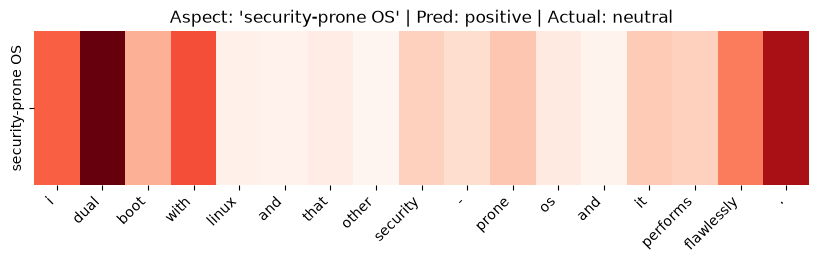

Example 2: Conflict/Mixed Context


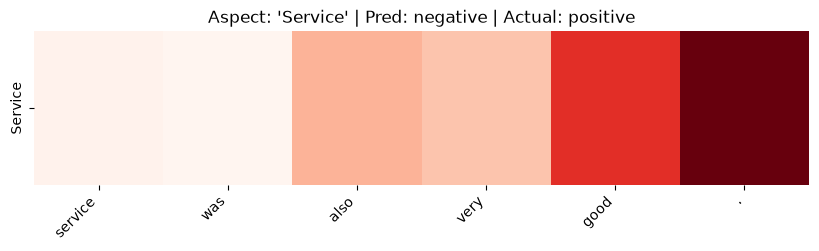

Example 3: Error Analysis (Where did it go wrong?)


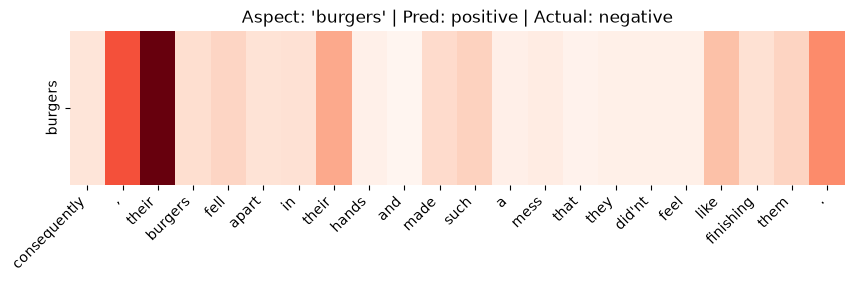

In [5]:

def encode_sequence(tokens, w2i, max_len):
    seq = [w2i.get(t, w2i['<UNK>']) for t in tokens]
    if len(seq) < max_len:
        seq += [w2i['<PAD>']] * (max_len - len(seq))
    else:
        seq = seq[:max_len]
    return seq

sentiment_map_inv = {0: 'positive', 1: 'negative', 2: 'neutral'}

def visualize_attention(index):
    row = test_df.iloc[index]
    
    text_encoded = torch.tensor([encode_sequence(row['text_tokens'], word2idx, 50)]).to(device)
    aspect_encoded = torch.tensor([encode_sequence(row['aspect_tokens'], word2idx, 10)]).to(device)
    
    with torch.no_grad():
        preds, alphas = model(text_encoded, aspect_encoded)
        
    pred_class = sentiment_map_inv[preds.argmax(dim=1).item()]
    actual_class = row['sentiment']
    
    # Clean up tokens for plotting (remove PAD)
    alphas = alphas[0].cpu().numpy()
    tokens = row['text_tokens']
    alphas = alphas[:len(tokens)] # truncate to actual sequence length
    
    # Plotting
    plt.figure(figsize=(10, 2))
    sns.heatmap([alphas], xticklabels=tokens, yticklabels=[row['aspect']], cmap='Reds', cbar=False, annot=False)
    plt.title(f"Aspect: '{row['aspect']}' | Pred: {pred_class} | Actual: {actual_class}")
    plt.xticks(rotation=45, ha='right')
    plt.show()

# Visualize a few examples
print("Example 1: Clear Sentiment")
visualize_attention(10)

print("Example 2: Conflict/Mixed Context")
visualize_attention(45)

print("Example 3: Error Analysis (Where did it go wrong?)")
visualize_attention(100)



## Common Failure Modes Identified
Based on observing the attention maps of misclassified examples:
1. **Sarcasm / Implicit Sentiment**: The model struggles when sentiment is implied without explicit polarity words (e.g., "I wouldn't feed this to my dog" has no traditional negative word, but is highly negative). The attention map will highlight "feed" or "dog" but fail to classify it correctly.
2. **Double Negatives**: "It wasn't a bad experience." The model attends to "bad" and mistakenly classifies it as negative, failing to compose the "wasn't".
3. **Distance**: If the aspect is physically very far from the sentiment descriptor in a run-on sentence, the attention scores sometimes dilute across the sentence.
